# E01 · Baseline model

A deliberately simple first model. Every later improvement is measured against it.

| Choice | Baseline |
|---|---|
| Model | EfficientNet-B0, pretrained on ImageNet, first layer adapted to 12 bands (≈ 4M parameters, medium track) |
| Input | all 12 bands, 64 × 64, standardised with the mean/std of the training split |
| Haze correction | none |
| Augmentation | random 90° rotations and flips |
| Training | AdamW, one-cycle learning rate, label smoothing 0.1, early stopping on validation accuracy |

**What this notebook produces** (in `runs/<date>_<name>/`):

| File | Content |
|---|---|
| `model.pt` | trained weights (state dict) |
| `config.json` | everything needed to rebuild the model: bands, normalisation, hyperparameters |
| `history.csv` | loss and accuracy per epoch |
| `metrics.json` | validation, internal test and Kaggle monitoring numbers |
| `submission.csv` | Kaggle submission file |

**Hardware.** Training runs on the GPU: CUDA if available, otherwise the Apple GPU (MPS), otherwise
the CPU. On an M4 one epoch takes about 40 seconds; on the CPU it would take over an hour.

**Train or load.** `LOAD_RUN` points to this experiment's saved run: the notebook loads its
weights and recomputes every result and the submission file in about a minute. Set
`LOAD_RUN = None` to train a new model (about 20 minutes on an M4 GPU).

## 1 · Setup

In [1]:
import json
import sys
from dataclasses import asdict
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from sklearn.metrics import classification_report

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir())
sys.path.insert(0, str(ROOT))
from src.data import CLASSES, PROJECT_ROOT, TEST_BANDS
from src.experiment import (class_mix, kaggle_monitor, load_experiment_data, plot_class_mix,
                            plot_confusion_matrix, plot_training_curves)
from src.models import MEDIUM_TRACK_LIMIT, build_model
from src.plot_style import apply_style
from src.training import (Normalizer, TrainConfig, fit, load_run, new_run_dir, predict_proba,
                          save_run, write_submission)
from src.utils import count_parameters, describe_device, get_device, seed_everything

apply_style()

# ---- Experiment settings ---------------------------------------------------------------
NOTEBOOK = "E01_baseline"
RUN_NAME = "baseline_effb0"
DESCRIPTION = "EfficientNet-B0, 12 bands, no correction"
LOAD_RUN = "runs/2026-10-12_0824_baseline_effb0"   # None = train a new model
CORRECTIONS = []   # applied to EuroSAT images, in this order
MODEL = "efficientnet_b0"
BANDS = list(TEST_BANDS)              # all 12 bands
SEED = 42
cfg = TrainConfig(epochs=20, batch_size=128, lr=1e-3, weight_decay=1e-4,
                  label_smoothing=0.1, patience=5, augment=True)
# -----------------------------------------------------------------------------------------

seed_everything(SEED)
device = get_device()              # CUDA > Apple GPU (MPS) > CPU
print("Device:", describe_device(device))

Device: Apple GPU (MPS)


## 2 · Data

EuroSAT images (train / val / internal test, split from `03_split`) are corrected with `CORRECTIONS`;
Kaggle images are used as they are. The normalisation statistics come from the training split only.

In [2]:
data = load_experiment_data(BANDS, CORRECTIONS, device)
normalizer = Normalizer.fit(data.X_tr)
print(data.summary())

train 18,900  val 4,050  internal test 4,050  Kaggle test 4,232


## 3 · Model and training

After every epoch the model also predicts the unlabelled Kaggle images, to watch the domain shift
without spending submissions (mean confidence, predicted class shares).

In [3]:
if LOAD_RUN:
    model, normalizer, _ = load_run(PROJECT_ROOT / LOAD_RUN, device)
    history = pd.read_csv(PROJECT_ROOT / LOAD_RUN / "history.csv")
    print(f"Loaded weights and training history ({len(history)} epochs) from {LOAD_RUN}: no training")
else:
    model = build_model(MODEL, bands=BANDS, pretrained=True).to(device)
    history, best_state = fit(model, data.tr_images, data.tr_labels, data.va_images, data.va_labels,
                              normalizer, cfg, monitor=kaggle_monitor(data, normalizer))

n_params = count_parameters(model)
assert n_params <= MEDIUM_TRACK_LIMIT, "too many parameters for the medium track"
print(f"{MODEL}: {n_params:,} parameters (medium track limit {MEDIUM_TRACK_LIMIT:,})")

Loaded weights and training history (20 epochs) from runs/2026-10-12_0824_baseline_effb0: no training
efficientnet_b0: 4,022,950 parameters (medium track limit 10,000,000)


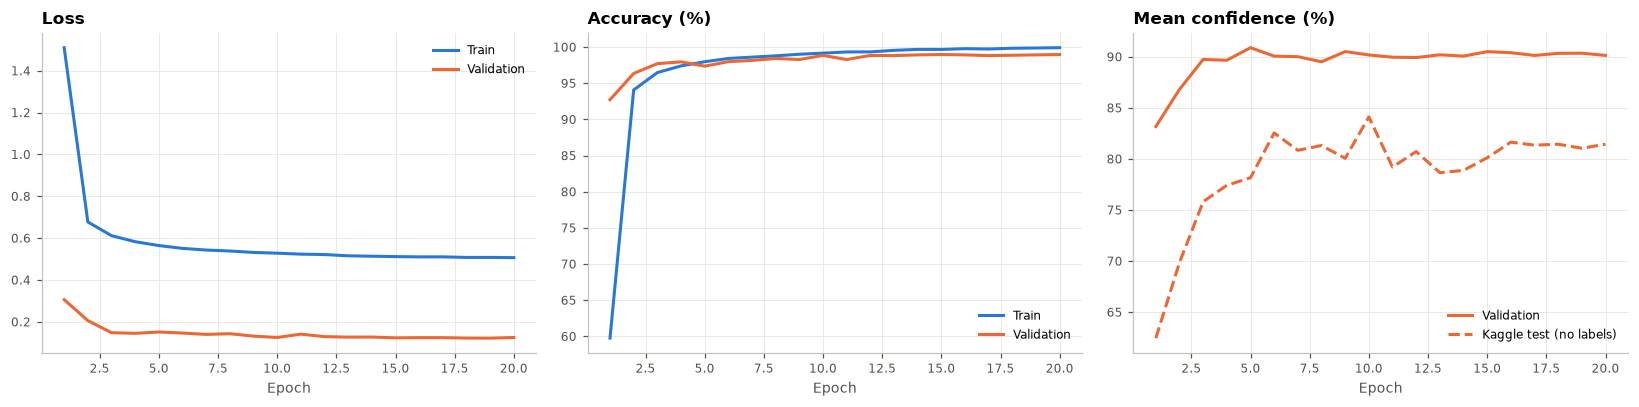

In [4]:
plot_training_curves(history)

## 4 · Internal test set

Measured once, on the best epoch: how well the model learned EuroSAT itself. It says nothing about
the Level-2A Kaggle images.

In [5]:
te_pred = predict_proba(model, data.te_images, normalizer).argmax(1)
val_acc = float(history["val_acc"].max())
test_acc = float((te_pred == data.y_te).mean())
print(f"Validation accuracy (best epoch): {val_acc:.2%}")
print(f"Internal test accuracy:           {test_acc:.2%}\n")
print(classification_report(data.y_te, te_pred, target_names=CLASSES, digits=3))

Validation accuracy (best epoch): 98.96%
Internal test accuracy:           98.79%

                      precision    recall  f1-score   support

          AnnualCrop      0.989     0.978     0.983       450
              Forest      0.996     1.000     0.998       450
HerbaceousVegetation      0.980     0.982     0.981       450
             Highway      0.989     0.981     0.985       375
          Industrial      0.992     0.995     0.993       375
             Pasture      0.970     0.970     0.970       300
       PermanentCrop      0.973     0.979     0.976       375
         Residential      1.000     0.996     0.998       450
               River      0.984     0.992     0.988       375
             SeaLake      0.998     1.000     0.999       450

            accuracy                          0.988      4050
           macro avg      0.987     0.987     0.987      4050
        weighted avg      0.988     0.988     0.988      4050



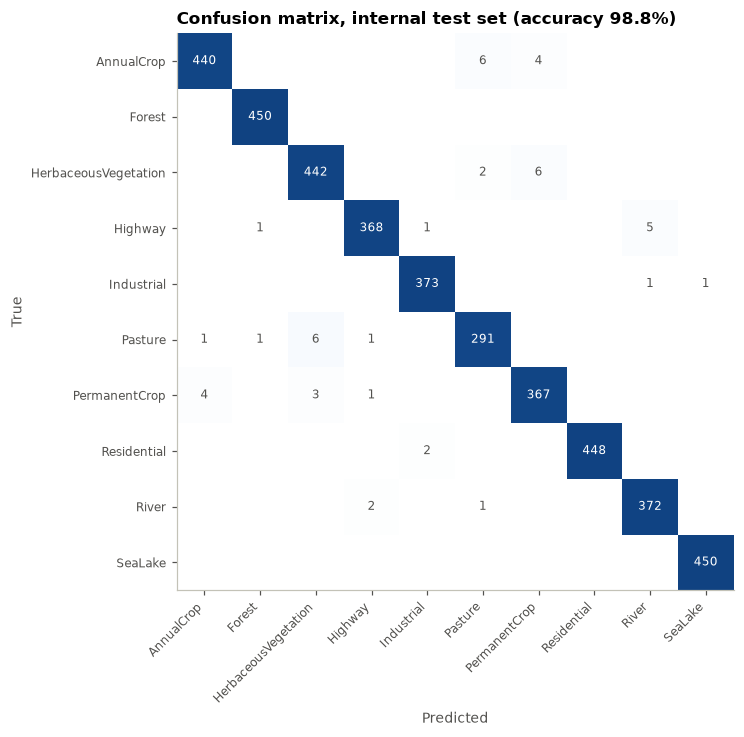

In [6]:
plot_confusion_matrix(data.y_te, te_pred, f"Confusion matrix, internal test set (accuracy {test_acc:.1%})")

## 5 · Kaggle predictions

Kaggle images as they are, normalised with the training statistics; test-time augmentation averages
the 8 rotations/flips of each image.

> **Tried and dropped:** normalising the Kaggle images with *their own* mean/std as a quick haze correction
> scored **47.82%** (vs **56.48%** for this baseline). The Kaggle set contains much more water, which skews its
> statistics, so this over-corrects. Proper corrections are compared in `04_haze_correction`.

Mean confidence on Kaggle images: 77.4%


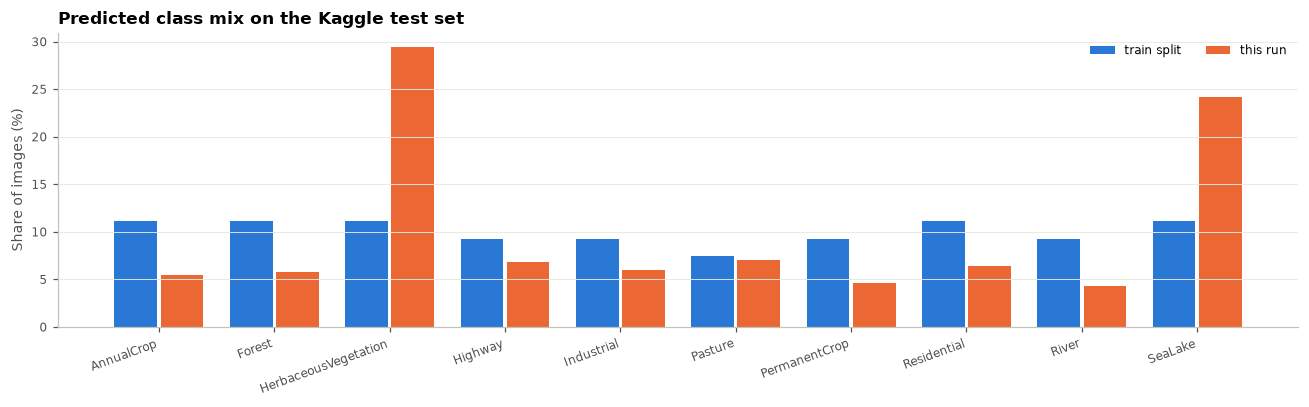

,AnnualCrop,Forest,HerbaceousVegetation,Highway,Industrial,Pasture,PermanentCrop,Residential,River,SeaLake
train split,11.1,11.1,11.1,9.3,9.3,7.4,9.3,11.1,9.3,11.1
this run,5.5,5.8,29.4,6.8,6.0,7.0,4.6,6.5,4.3,24.1


In [7]:
kg_prob = predict_proba(model, data.kg_images, normalizer, tta=True)
kg_conf = float(kg_prob.max(1).mean())
mix = pd.DataFrame({"train split": class_mix(np.eye(10)[data.y_tr]), "this run": class_mix(kg_prob)})
print(f"Mean confidence on Kaggle images: {kg_conf:.1%}")
plot_class_mix(mix)
mix.round(1).T

## 6 · Save the run

With `LOAD_RUN` nothing is retrained or overwritten except `submission.csv`, recomputed from the saved weights.

In [8]:
if LOAD_RUN:
    run_dir = PROJECT_ROOT / LOAD_RUN
else:
    run_dir = new_run_dir(RUN_NAME)
    config = {
        "run_name": run_dir.name, "description": DESCRIPTION, "notebook": NOTEBOOK, "model": MODEL,
        "bands": BANDS, "seed": SEED, "n_params": n_params, "device": describe_device(device),
        "normalizer": asdict(normalizer), "corrections": CORRECTIONS, "train": asdict(cfg),
        "split": "split_seed42",
    }
    metrics = {
        "val_acc": val_acc, "internal_test_acc": test_acc,
        "best_epoch": int(history.loc[history["val_acc"].idxmax(), "epoch"]),
        "kaggle_mean_confidence": kg_conf,
        "kaggle_predicted_mix_pct": mix["this run"].round(2).to_dict(),
        "kaggle_public_score": None,  # fill in after submitting
    }
    save_run(run_dir, best_state, config, history, metrics)

write_submission(kg_prob, data.test_ids, run_dir / "submission.csv")
print("Run folder:", run_dir.relative_to(PROJECT_ROOT))
for f in sorted(run_dir.iterdir()):
    print(f"  {f.name:20} {f.stat().st_size / 1e6:6.2f} MB")

Run folder: runs/2026-10-12_0824_baseline_effb0
  config.json            0.00 MB
  history.csv            0.01 MB
  metrics.json           0.00 MB
  model.pt              16.35 MB
  submission.csv         0.07 MB


## 7 · Result

**Kaggle public score: 56.48%** (internal test 98.79%), so the domain shift costs about 42 points.
The model learns EuroSAT almost perfectly; all later experiments work on the shift, one change at a time:
haze correction (`04_haze_correction`, `E02_hist_split`), AdaBN (`E03`), contrast augmentation (`E04`),
Fourier methods (`E05`–`E07`). Overview: `00_results_overview`.